# Part II - Ford GoBike Trip Data: Explanatory Analysis
## by Eduardo Nicacio

## Investigation Overview

> **Theme: Understanding what drives trip duration in the Ford GoBike system.**

This deck covers **174,955 cleaned trips** from February 2019, using the same cleaning pipeline as Part I so the numbers match the exploration.

**Executive summary of key insights:**

1. **Trip durations are right-skewed; log-transformation reveals a near-normal distribution** - the median trip lasts **~8.5 minutes**, and 96.5% stay under 30.
2. **Casual Customers ride roughly 2× longer than Subscribers** - 21.8 vs. 10.7 minutes on average.
3. **Subscriber usage is weekday commuting** - sharp 8 AM and 5–6 PM spikes, with weekends flattening into midday leisure riding.
4. **Age peaks in the late 20s–early 30s** (median 32) - but it doesn't move trip length.
5. **Gender changes who rides, not how long** - Male ≈ 74.6% of trips, with nearly identical duration distributions across levels.

*Note: the dataset for this analysis is provided with Udacity's project materials.*

In [1]:
# import all packages and set plots to be embedded inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

# project-wide style: one professional blue plus shared seaborn/grid settings
BASE_COLOR = "#2E86AB"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (8, 5)

In [2]:
USER_ORDER = ["Subscriber", "Customer"]
DAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday",
             "Friday", "Saturday", "Sunday"]

def add_labels(ax, title, xlabel, ylabel):
    """Apply a consistent title and labeled axes to a plot axes.

    Args:
        ax: matplotlib axes to format.
        title: plot title text.
        xlabel: x-axis label text including units.
        ylabel: y-axis label text including units.

    Returns:
        The same axes object, so calls can be chained.
    """
    ax.set_title(title, fontsize=15, fontweight="bold")
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    return ax


def plot_hist(ax, data, column, bins, color=BASE_COLOR):
    """Draw a histogram of a numeric column with consistent styling.

    Args:
        ax: axes to draw on.
        data: DataFrame holding the column.
        column: name of the numeric column to plot.
        bins: sequence of bin edges, or an integer number of bins.
        color: fill color for the bars.

    Returns:
        The same axes object, so calls can be chained.
    """
    ax.hist(data=data, x=column, bins=bins, color=color,
            edgecolor="white", linewidth=0.4)
    return ax


def plot_count(ax, data, column, color=BASE_COLOR):
    """Draw a frequency bar chart ordered by count, with value annotations.

    Bars are ordered by frequency, and each bar is labeled with its count
    and share of trips, so both ranking and imbalance stay readable.

    Args:
        ax: axes to draw on.
        data: DataFrame holding the column.
        column: name of the categorical column to plot.
        color: fill color for the bars.

    Returns:
        The same axes object, so calls can be chained.
    """
    counts = data[column].value_counts()  # order bars by frequency
    ax.bar(x=range(len(counts)), height=counts.values, color=color)
    ax.set_xticks(range(len(counts)), counts.index)  # category names under bars
    total = counts.sum()  # used to convert each count into a share
    for i, value in enumerate(counts.values):
        ax.text(i, value + total * 0.01, f"{value:,}\n({value / total:.1%})",
                ha="center", va="bottom", fontsize=10)
    return ax


def pivot_hour_by_day(data):
    """Build a day-of-week x hour-of-day pivot table of trip counts.

    Rows are ordered Monday->Sunday and all 24 hours are kept, so heatmaps
    built later always communicate the same grid shape.

    Args:
        data: DataFrame with `day_of_week` and `hour_of_day` columns.

    Returns:
        A 7x24 DataFrame of integer trip counts.
    """
    day_order = ["Monday", "Tuesday", "Wednesday", "Thursday",
                 "Friday", "Saturday", "Sunday"]
    # count trips per day/hour combination, then spread hours into columns
    piv = data.groupby(["day_of_week", "hour_of_day"], observed=True).size().unstack(fill_value=0)
    piv = piv.reindex(index=day_order, columns=range(24), fill_value=0)
    return piv

### Data loading

The cleaning pipeline from Part I is encapsulated in one reusable function so the presented data is identical to the explored data - same filters, same derived columns.

In [3]:
def load_and_clean(csv_path):
    """Load and clean the Ford GoBike trip data for presentation plots.

    Replicates the Part I pipeline: drop unusable durations, convert to
    minutes, derive time-of-day and age features, and cast categories.

    Args:
        csv_path: path to the raw 201902-fordgobike-tripdata.csv file.

    Returns:
        A cleaned DataFrame with derived analysis columns added.
    """
    trips = pd.read_csv(csv_path)

    # keep only rows with a usable, positive trip duration
    trips = trips[trips["duration_sec"].notna() & (trips["duration_sec"] > 0)]

    # minutes are the natural reporting unit for this range of trips
    trips["duration_min"] = trips["duration_sec"] / 60.0

    # parse timestamps into the time features used in the presentation
    trips["start_time"] = pd.to_datetime(trips["start_time"])
    trips["hour_of_day"] = trips["start_time"].dt.hour
    day_dtype = pd.api.types.CategoricalDtype(categories=DAY_ORDER, ordered=True)
    trips["day_of_week"] = trips["start_time"].dt.day_name().astype(day_dtype)

    # derive rider age, bounded to plausible values
    trips["member_age"] = 2019 - trips["member_birth_year"]
    trips = trips[trips["member_age"].between(16, 80)]

    # few distinct values per descriptive column; category dtype saves memory
    for column in ["user_type", "member_gender", "bike_share_for_all_trip"]:
        trips[column] = trips[column].astype("category")

    return trips


trips = load_and_clean("data/201902-fordgobike-tripdata.csv")
print("Presenting {} trips after cleaning.".format(len(trips)))

Presenting 174955 trips after cleaning.


In [4]:
# claim-verification: headline numbers quoted in this notebook's markdown,
# recomputed from the same cleaned table so each sentence traces to a value

duration = trips["duration_min"]
age = trips["member_age"]
print("median trip:", round(duration.median(), 2), "min | total trips:", len(trips))
print("duration range: {:.2f} to {:.0f} min ({:.1f} hours)".format(
    duration.min(), duration.max(), duration.max() / 60))
print("trips > 30 min: {:.1%} | riders > 60 years: {:.1%}".format(
    (duration > 30).mean(), (age > 60).mean()))
print(trips.groupby("user_type", observed=True)["duration_min"]
      .agg(["median", "mean"]).round(2))
print("share of trips > 60 min by user type (%):")
print((trips.groupby("user_type", observed=True)["duration_min"]
       .apply(lambda d: (d > 60).mean()) * 100).round(2))
print("subscribers: {:.1%} of all trips".format((trips["user_type"] == "Subscriber").mean()))
for user in ["Subscriber", "Customer"]:
    hour_counts = trips[trips["user_type"] == user].groupby("hour_of_day", observed=True).size()
    mid_share = hour_counts.loc[10:16].sum() / hour_counts.sum()
    print(user, "| busiest hour:", int(hour_counts.idxmax()), "with",
          int(hour_counts.max()), "trips | share 10 AM-4 PM: {:.0%}".format(mid_share))
print(trips["member_gender"].value_counts())
print((trips["member_gender"].value_counts(normalize=True) * 100).round(1))

median trip: 8.52 min | total trips: 174955
duration range: 1.02 to 1409 min (23.5 hours)
trips > 30 min: 3.4% | riders > 60 years: 1.9%
            median   mean
user_type                
Customer     13.00  21.84
Subscriber    8.17  10.68
share of trips > 60 min by user type (%):
user_type
Customer      4.22
Subscriber    0.43
Name: duration_min, dtype: float64
subscribers: 90.5% of all trips
Subscriber | busiest hour: 17 with 18886 trips | share 10 AM-4 PM: 34%
Customer | busiest hour: 17 with 2024 trips | share 10 AM-4 PM: 46%
member_gender
Male      130496
Female     40810
Other       3649
Name: count, dtype: int64
member_gender
Male      74.6
Female    23.3
Other      2.1
Name: proportion, dtype: float64


## Visualization 1 - How long is a typical trip?

Trips range from about one minute to nearly a full day, so the distribution is presented on a log-scaled axis with a dashed line marking the median - otherwise the handful of overnight trips would crush every short commute into one bar.

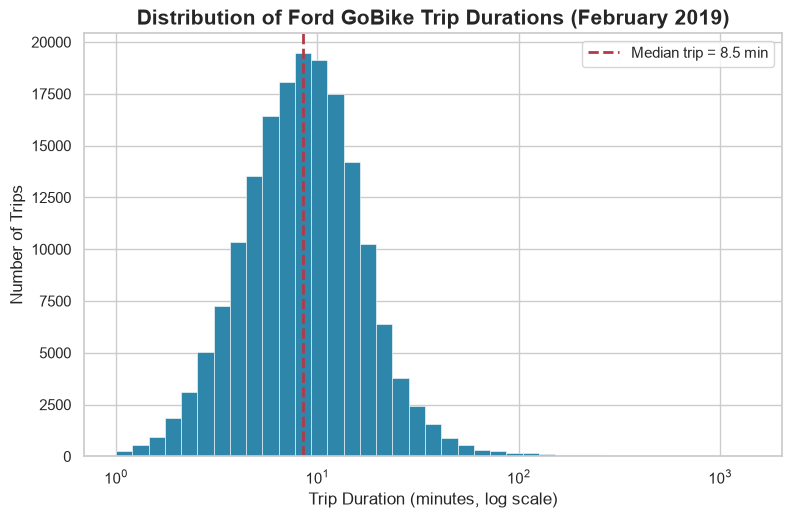

In [5]:
# log-spaced bins spread the heavy right tail evenly across the axis
duration_bins = np.logspace(np.log10(1), np.log10(trips["duration_min"].max()), 40)
typical_min = trips["duration_min"].median()

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.hist(trips["duration_min"], bins=duration_bins, color="#2E86AB",
        edgecolor="white", linewidth=0.4)
ax.set_xscale("log")
# dashed reference line flags the typical trip in a long-tailed distribution
ax.axvline(typical_min, color="#B23A48", linestyle="--", linewidth=2,
           label="Median trip = {:.1f} min".format(typical_min))
ax.legend(loc="upper right")
add_labels(ax, "Distribution of Ford GoBike Trip Durations (February 2019)",
           "Trip Duration (minutes, log scale)", "Number of Trips");

**Observation:** The median trip is **8.5 minutes**. On the log scale the histogram looks near-normal around that peak: **96.5%** of trips finish within 30 minutes, and a thin tail reaches ~23 hours. Short rides are the norm here - the variation worth explaining is *who* is riding them, which is the next chart.

## Visualization 2 - Who rides how long?

Duration by user type is the most **actionable** insight of the analysis: Subscribers are morning-and-evening commuters, while casual Customers are leisure riders - and their contract structures should follow. Box plots on a log axis, with each box's median annotated, make the two-to-one gap explicit.

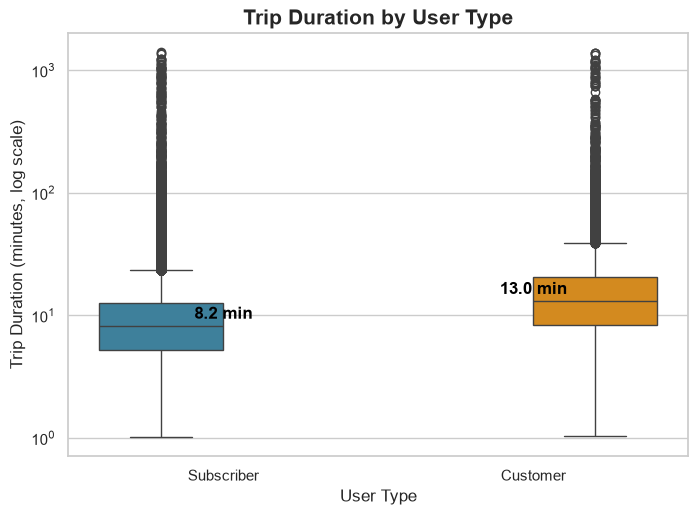

In [6]:
user_palette = {"Subscriber": "#2E86AB", "Customer": "#F18F01"}

fig, ax = plt.subplots(figsize=(8, 5.5))
sns.boxplot(data=trips, x="user_type", y="duration_min", order=USER_ORDER,
            hue="user_type", hue_order=USER_ORDER, legend=False,
            palette=user_palette, ax=ax)
ax.set_yscale("log")
# annotate each box with its median so the gap is quantified in the chart itself
medians = trips.groupby("user_type", observed=True)["duration_min"].median()
for i, user in enumerate(USER_ORDER):
    ax.text(i, medians[user] * 1.15, "{:.1f} min".format(medians[user]),
            ha="center", fontweight="bold", color="black")
add_labels(ax, "Trip Duration by User Type", "User Type",
           "Trip Duration (minutes, log scale)");

**Observation:** The 2× gap is the headline: Customers median **13.0 min**, mean **21.8 min**, against Subscribers at **8.2** and **10.7**. On the rates side, 4.2% of Customer trips go past an hour vs. 0.4% for Subscribers - a 10× difference. The read: Subscribers run quick, fixed-purpose commutes; Customers behave like leisure or occasional riders. That is why the printed medians matter more than the whiskers on a log axis.

## Visualization 3 - When is the system used?

The user-type contrast above predicts *when* rides happen, so this heatmap connects the two: weekday rows carry two sharp commute ridges, driven almost entirely by Subscribers (90.5% of trips), while weekends shift to a broad midday leisure band.

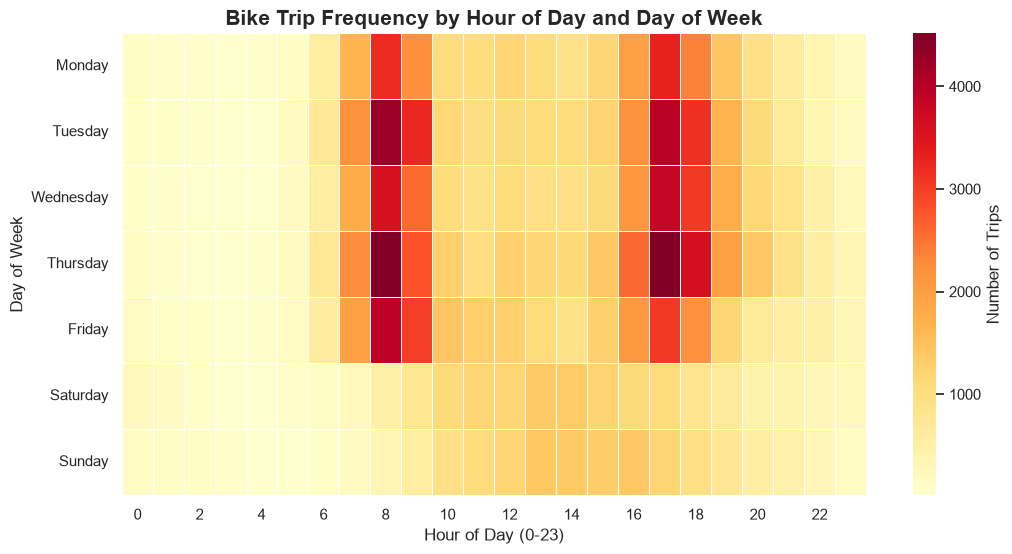

In [7]:
hour_day = pivot_hour_by_day(trips)

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(hour_day, cmap="YlOrRd", linewidths=0.5, linecolor="white",
            cbar_kws={"label": "Number of Trips"}, ax=ax)
# keep only every second hour label so the axis stays readable
ax.set_xticks(np.arange(0.5, 24.5, 2), labels=np.arange(0, 24, 2))
add_labels(ax, "Bike Trip Frequency by Hour of Day and Day of Week",
           "Hour of Day (0-23)", "Day of Week");

**Observation:** Weekday ridges sit at **8 AM and 5–6 PM**, and they belong mostly to Subscribers (90.5% of trips). Weekends flatten into a **10 AM–4 PM** band. Practical read: rebalancing and maintenance capacity should follow the double weekday peak, while casual-pass marketing is best aimed at the weekend midday crowd.

## Visualization 4 - One system, two usage patterns

Finally, the two user rhythms side by side, on a shared y-scale so the volume difference stays honest: Subscribers' twin commute spikes versus Customers' broad leisure hump.

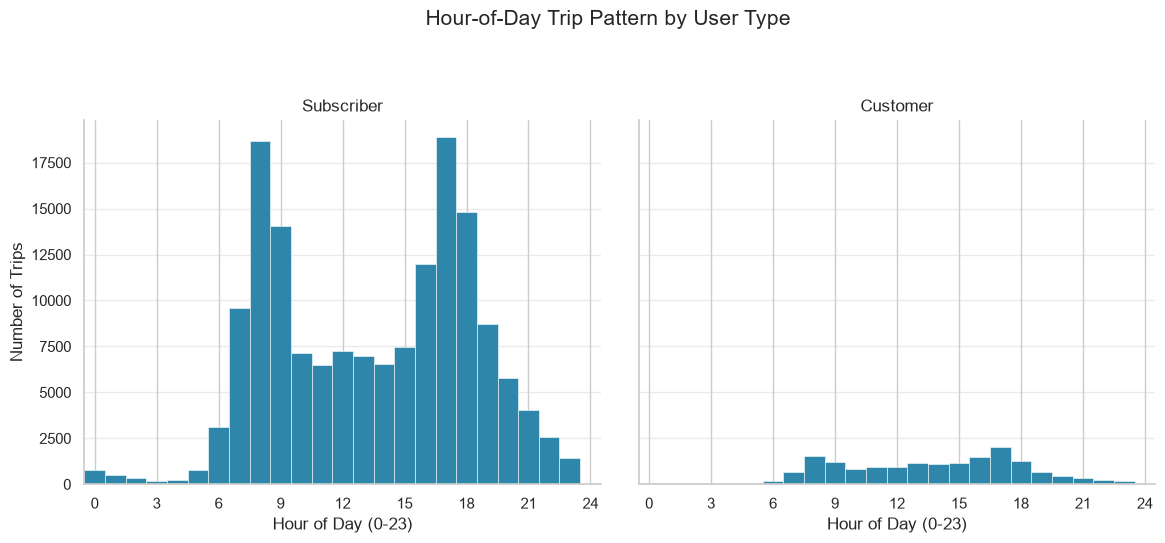

In [8]:
def plot_hour_hist(ax, data, **hist_kwargs):
    """Draw the hour-of-day histogram on one facet of the user-type grid.

    Args:
        ax: the facet axes to draw on.
        data: one-user-type slice of the cleaned trip data.
        **hist_kwargs: forwarded to ``ax.hist`` (bins, color, styling).

    Returns:
        The same axes object, so calls can be chained.
    """
    ax.hist(data["hour_of_day"], **hist_kwargs)
    return ax


# shared y-axis keeps the Subscriber/Customer volume contrast honest across panels
g = sns.FacetGrid(data=trips, col="user_type", col_order=USER_ORDER,
                  height=5, aspect=1.15, sharey=True)
hour_bins = np.arange(-0.5, 25.5, 1)  # one centered bin per hour 0-23
for user_type, ax in zip(USER_ORDER, g.axes.flat):
    # slice each panel manually so the facet data is never ambiguous
    plot_hour_hist(ax, trips.loc[trips["user_type"] == user_type],
                   bins=hour_bins, color="#2E86AB",
                   edgecolor="white", linewidth=0.4)
    sparse_ticks = list(range(0, 25, 3))  # sparse ticks keep hour labels readable
    ax.set_xlim(-0.5, 24.5)
    ax.set_xticks(sparse_ticks, labels=sparse_ticks)
g.set_titles("{col_name}")  # panel headers name the user type
g.set_xlabels("Hour of Day (0-23)")
g.set_ylabels("Number of Trips")
# overall suptitle frames the comparison for the slide deck
g.figure.suptitle("Hour-of-Day Trip Pattern by User Type", fontsize=15, y=1.04)
g.figure.subplots_adjust(top=0.82)
for ax in g.axes.flat:
    ax.grid(True, axis="y", alpha=0.4);

**Observation:** Same y-axis, two different days: Subscribers get two towers (**8 AM, 5–6 PM**); Customers get one broad hill from late morning through early evening. Customers' busiest hour (5 PM, 2,024 trips) is about a tenth of Subscribers' 5 PM bar, and 46% of Customer trips fall in the 10 AM–4 PM window - so the heatmap's weekend/midday band is, at least in part, a *customer* pattern the combined statistics hide.

---

**Notebook exported as HTML for submission.**